# 5. Designing for an uncertain future

**Goal of this notebook:** choose the network the way a company actually has to: once, before knowing what demand will do.

Notebooks 2 to 4 optimized the network for the year that already happened. A real network is built once and then used for years. In that time demand grows, and not evenly. Between the first eight months of 2017 and the same months of 2018, Olist's volume grew 2.4 times, and the growth rate differed a lot from state to state. Buildings also have limits and cost money to run, whether they are full or not.

So this notebook adds three things to the model of notebook 2:

1. **A fixed yearly cost per building**, so the model decides how many centers to open instead of being told.
2. **Two building sizes with a capacity each.** Orders beyond a building's capacity ship direct from the seller.
3. **Many possible futures at once.** Sites and sizes are decided now. In each future, orders are routed as well as possible given the buildings that exist.

This is a **two-stage stochastic program**, a standard tool for decisions that are made under uncertainty and are hard to undo. The questions are:

- How much does it cost to plan for last year instead of for the future?
- Does modeling the uncertainty pay, compared with planning for the single most likely future?
- How do you trade a better average against protection in the bad futures?
- What does a delivery promise cost?

The model lives in `src/stochastic_model.py`. It uses the HiGHS solver through PuLP, because these models are much larger than the ones in notebook 2.

In [1]:
import sys
sys.path.insert(0, "../src")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import network_model as nm
import stochastic_model as sm
from helpers import COLORS, RESULTS, pretty_city, save_figure, set_chart_style

set_chart_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

data = nm.prepare()
regions, region_of_city = sm.aggregate(data)
states = sorted(set(regions.state))
print(f"{data.n_cities:,} customer cities grouped into {len(regions.names)} regions, {data.n_sites} candidate sites")


def site_list(built):
    """Readable list of buildings: city name, with (L) for a large building."""
    return ", ".join(pretty_city(regions.site_names[j]) + (" (L)" if k == "large" else "") for j, k in built)

3,811 customer cities grouped into 301 regions, 60 candidate sites


## Step 1. Make the model small enough to solve many futures at once

Notebook 2 had 3,811 customer cities. With 50 futures the model would need tens of millions of variables. So small towns are grouped with the nearest large city in their own state. The 300 cities with the most items, every candidate site and the largest city of every state keep their own demand point, and every other city joins the nearest of those in its state.

Grouping is an approximation, so check it: price notebook 2's six-center network both ways.

In [2]:
six = nm.best_network(data, 6)
C = regions.fc_cost()
grouped_cost = np.minimum(C[:, six["sites"]].min(axis=1), regions.direct_cost).sum()
print(f"Six-center network, city by city (notebook 2): R$ {six['cost']:,.0f}")
print(f"Same network, grouped into regions:            R$ {grouped_cost:,.0f}  ({100 * (grouped_cost / six['cost'] - 1):+.2f}%)")

Six-center network, city by city (notebook 2): R$ 1,503,533
Same network, grouped into regions:            R$ 1,509,042  (+0.37%)


The grouped model is within half a percent of the city-level model. That is close enough to compare designs, which is all it is used for.

## Step 2. The assumptions this notebook adds

The data cannot tell us what a building costs or how big it is, so these are assumptions, chosen to be in proportion with the rest of the model and tested in Step 7:

In [3]:
sm.SIZES

,fixed_cost,capacity
small,"15,000.00","20,000.00"
large,"25,000.00","50,000.00"


- **Fixed cost** is a yearly cost for running the building (rent, staff, systems), in R\$. For scale, notebook 4 found that centers 3 to 7 each add R\$13,000 to R\$18,000 a year of net saving, so R\$15,000 for a small building puts the model right at the margin where the decision is interesting.
- **Capacity** is items a year. A small building can handle the volume of any center in notebook 2 except Osasco (28,810 items) and Nova Iguaçu (12,288 items, with room to grow). A large building is a bit more than twice as big for two-thirds more cost, a typical economy of scale.

## Step 3. Possible futures, built from the data

Each future gives every state a demand multiplier: how many items it orders compared with the study year.

**multiplier = national growth x regional deviation**

- **National growth** is uncertain. Its median is 1.5 (half again as many items as in the study year) and it ranges roughly from 0.9 to 2.4 across the futures. Olist's volume had grown 2.4 times in a year but was flat across 2018, so both fast and slow growth are plausible.
- **Regional deviation** is how much a state's growth differs from the national rate. In the data, the spread of state growth around the national rate was 0.13 on a log scale for one year when weighted by volume (0.25 unweighted). The futures use 0.20, a middle value for a horizon of a few years.

In [4]:
growth = pd.read_sql(
    """SELECT c.customer_state AS state, strftime('%Y', o.order_purchase_timestamp) AS year, COUNT(*) AS items
       FROM order_items oi JOIN orders o ON o.order_id = oi.order_id
       JOIN customers c ON c.customer_id = o.customer_id
       WHERE o.order_status = 'delivered' AND strftime('%m', o.order_purchase_timestamp) BETWEEN '01' AND '08'
       GROUP BY state, year""",
    nm.connect(),
).pivot(index="state", columns="year", values="items")
national = growth["2018"].sum() / growth["2017"].sum()
relative = np.log(growth["2018"] / growth["2017"]) - np.log(national)
weight = growth["2018"] / growth["2018"].sum()
print(f"National growth, Jan-Aug 2017 to Jan-Aug 2018: x{national:.2f}")
print(f"Spread of state growth around it (log scale): {np.sqrt((weight * relative**2).sum()):.2f} weighted by volume, "
      f"{relative.std():.2f} unweighted")

design_futures = sm.make_scenarios(states, 50, seed=1)     # the model plans with these
test_futures = sm.make_scenarios(states, 300, seed=99)    # and is judged on these, which it never saw
total_items = lambda f: float((np.array([f[s] for s in regions.state]) * regions.items).sum())
volumes = np.array([total_items(test_futures.iloc[s]) for s in range(len(test_futures))])
print(f"\nItems a year across the 300 test futures: 10th percentile {np.percentile(volumes, 10):,.0f}, "
      f"median {np.median(volumes):,.0f}, 90th percentile {np.percentile(volumes, 90):,.0f} "
      f"(study year: {regions.items.sum():,.0f})")

National growth, Jan-Aug 2017 to Jan-Aug 2018: x2.42
Spread of state growth around it (log scale): 0.13 weighted by volume, 0.25 unweighted

Items a year across the 300 test futures: 10th percentile 91,457, median 132,178, 90th percentile 179,394 (study year: 84,523)


Two separate sets of futures are used, just as a forecast is tested on weeks it was not fitted on. The model plans with 50 futures. Every design is then judged on 300 different futures that no design has seen.

## Step 4. Three ways to plan

1. **Plan for last year:** optimize for the study year's demand, as notebooks 2 to 4 did, but now with fixed costs and capacities.
2. **Plan for the average future:** optimize for one future in which every state grows by its average multiplier. This is what a planner with a single forecast would do.
3. **Plan for all the futures (stochastic):** optimize the average result over the 50 planning futures at once.

For each design, `sm.operate` routes each test future's orders as cheaply as possible through the buildings that exist, with overflow shipped direct. The score is the **net saving**: the freight saved compared with shipping everything direct, minus the buildings' fixed costs.

In [5]:
def judge(built, futures=test_futures):
    """Net saving and service of a design in every future."""
    fixed = sum(sm.SIZES.at[k, "fixed_cost"] for _, k in built)
    rows = pd.DataFrame([sm.operate(regions, built, futures.iloc[s]) for s in range(len(futures))])
    rows["net_saving"] = rows["baseline_cost"] - rows["cost"] - fixed
    return rows


def worst_tenth(values):
    """Average of the worst 10% of values."""
    values = np.sort(np.asarray(values))
    return values[: max(1, len(values) // 10)].mean()


start = time.time()
plans = {
    "last year": sm.design(regions, pd.DataFrame([{s: 1.0 for s in states}])),
    "average future": sm.design(regions, pd.DataFrame([design_futures.mean()])),
    "all futures (stochastic)": sm.design(regions, design_futures),
}
judged = {name: judge(plan["sites"]) for name, plan in plans.items()}
print(f"Solved and judged in {time.time() - start:.0f} s\n")

comparison = pd.DataFrame({
    name: {
        "centers": len(plans[name]["sites"]),
        "large buildings": sum(k == "large" for _, k in plans[name]["sites"]),
        "fixed cost (R$)": plans[name]["fixed_cost"],
        "average net saving (R$)": j["net_saving"].mean(),
        "worst 10% of futures (R$)": worst_tenth(j["net_saving"]),
        "two-day delivery (%)": j["two_day_pct"].mean(),
        "days in transit": j["transit_days"].mean(),
    }
    for name, j in judged.items()
}).T
for name, plan in plans.items():
    print(f"{name:25s} {site_list(plan['sites'])}")
comparison

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


Solved and judged in 145 s

last year                 Brasilia, Porto Alegre, Salvador, Santo Andre, Nova Iguacu, Contagem, Teresina
average future            Brasilia, Curitiba, Porto Alegre, Salvador, Osasco (L), Recife, Nova Iguacu, Contagem, Serra, Teresina
all futures (stochastic)  Brasilia, Curitiba, Porto Alegre, Salvador, Recife, Nova Iguacu, Contagem, Vila Velha, Sao Caetano do Sul (L), Teresina


,centers,large buildings,fixed cost (R$),average net saving (R$),worst 10% of futures (R$),two-day delivery (%),days in transit
last year,7.00,0.00,"105,000.00","204,863.47","92,723.08",49.01,4.60
average future,10.00,1.00,"160,000.00","223,850.63","76,806.30",61.38,3.76
all futures (stochastic),10.00,1.00,"160,000.00","223,879.44","76,568.85",61.03,3.77


**What this shows.**

- **Planning for last year costs about R\$19,000 a year**, about 8% of the saving available. The last-year plan opens seven small buildings. In the future, demand has grown and the São Paulo and Rio de Janeiro buildings are full, so the extra orders ship direct at full price. The plans made for the future open ten centers, with a large building in the São Paulo metro area.
- **The stochastic plan and the average-future plan are worth the same.** Their average net savings differ by about R\$30 a year. In the textbook language, the *value of the stochastic solution* is essentially zero here. The reason is the ship-direct option. When a building turns out too small, the overflow simply ships the way it does today, so being wrong about one region costs little. Stochastic planning pays most when a wrong guess is expensive to fix, and here it is not.

That second finding is worth saying out loud in an interview: the more sophisticated model was tested and did not beat the simple one, and the reason is understood. What does matter is planning for growth at all.

How much better could any plan do with perfect foresight? Solve each test future on its own as if it were known in advance ("wait and see"). The gap to the stochastic plan is the **expected value of perfect information**: the most it would be worth paying for a perfect forecast.

In [6]:
start = time.time()
first = test_futures.iloc[:100]
foresight = [-sm.design(regions, first.iloc[[s]].reset_index(drop=True))["objective"] for s in range(len(first))]
stochastic_on_first = judged["all futures (stochastic)"]["net_saving"].iloc[:100].mean()
print(f"First 100 test futures ({time.time() - start:.0f} s):")
print(f"  stochastic plan, average net saving:      R$ {stochastic_on_first:,.0f}")
print(f"  with perfect foresight of each future:    R$ {np.mean(foresight):,.0f}")
print(f"  value of perfect information:             R$ {np.mean(foresight) - stochastic_on_first:,.0f} a year "
      f"({100 * (np.mean(foresight) / stochastic_on_first - 1):.0f}%)")

First 100 test futures (43 s):
  stochastic plan, average net saving:      R$ 230,779
  with perfect foresight of each future:    R$ 237,121
  value of perfect information:             R$ 6,342 a year (3%)


A perfect forecast of the next few years would add only about 3% to the saving, about R\$6,300 a year. Most of the value comes from building roughly the right network, which can be done without knowing the future.

/tmp/ipykernel_2149/3600652289.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = ax.boxplot(values, vert=False, widths=0.5, patch_artist=True, showfliers=False,


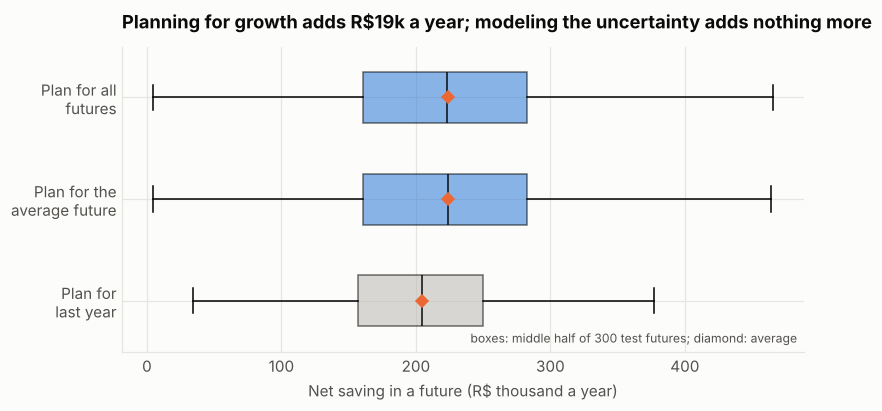

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = ["last year", "average future", "all futures (stochastic)"]
values = [judged[name]["net_saving"] / 1000 for name in order]
box = ax.boxplot(values, vert=False, widths=0.5, patch_artist=True, showfliers=False,
                 medianprops={"color": COLORS["text"]})
for patch, color in zip(box["boxes"], [COLORS["gray"], COLORS["blue"], COLORS["blue"]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)
for i, v in enumerate(values, start=1):
    ax.plot(v.mean(), i, marker="D", color=COLORS["orange"], markersize=6, zorder=3)
ax.set_yticks([1, 2, 3], ["Plan for\nlast year", "Plan for the\naverage future", "Plan for all\nfutures"])
ax.set_xlabel("Net saving in a future (R$ thousand a year)")
ax.set_title("Planning for growth adds R$19k a year; modeling the uncertainty adds nothing more")
ax.text(0.99, 0.02, "boxes: middle half of 300 test futures; diamond: average", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8, color=COLORS["muted"])
save_figure(fig, "05_plans_compared.png")
plt.show()

## Step 5. Average result versus protection in bad futures

The stochastic plan maximizes the average. But a company may care more about the bad futures, where demand grows slowly and buildings sit half empty. The model can weigh those directly. With a **risk weight** above zero, part of the objective becomes the average result in the worst 10% of futures, a measure called conditional value at risk (CVaR). It is written as a few extra linear constraints, so the model stays a mixed-integer program.

Each risk weight takes about two minutes to solve.

In [8]:
start = time.time()
frontier = []
for risk_weight in [0.0, 0.3, 0.6, 0.9]:
    plan = sm.design(regions, design_futures, risk_weight=risk_weight)
    j = judge(plan["sites"])
    frontier.append({
        "risk weight": risk_weight,
        "centers": len(plan["sites"]),
        "average net saving (R$)": j["net_saving"].mean(),
        "worst 10% of futures (R$)": worst_tenth(j["net_saving"]),
        "sites": site_list(plan["sites"]),
    })
frontier = pd.DataFrame(frontier).set_index("risk weight")
print(f"Solved in {time.time() - start:.0f} s")
frontier

Solved in 528 s


,centers,average net saving (R$),worst 10% of futures (R$),sites
risk weight,,,,
0.00,10,"223,879.44","76,568.85","Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
0.30,9,"222,539.96","81,934.31","Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
0.60,8,"210,012.95","90,141.09","Brasilia, Curitiba, Porto Alegre, Salvador, No..."
0.90,7,"204,833.92","92,785.51","Brasilia, Porto Alegre, Salvador, Nova Iguacu,..."


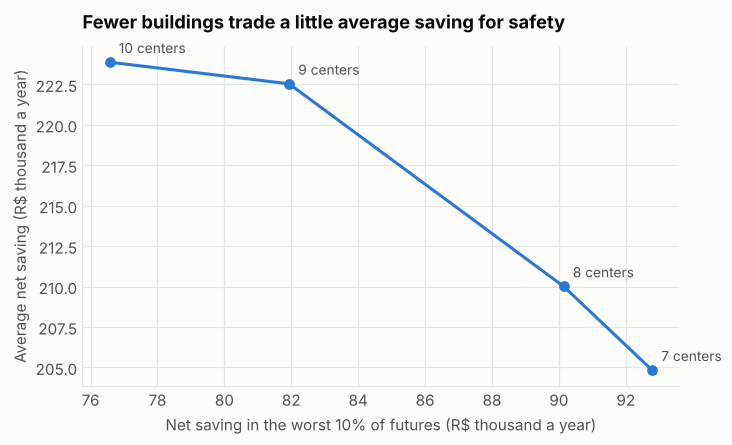

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(frontier["worst 10% of futures (R$)"] / 1000, frontier["average net saving (R$)"] / 1000,
        marker="o", color=COLORS["blue"])
for w, row in frontier.iterrows():
    ax.annotate(f"{row['centers']} centers", (row["worst 10% of futures (R$)"] / 1000, row["average net saving (R$)"] / 1000),
                textcoords="offset points", xytext=(6, 6), fontsize=9, color=COLORS["muted"])
ax.set_xlabel("Net saving in the worst 10% of futures (R$ thousand a year)")
ax.set_ylabel("Average net saving (R$ thousand a year)")
ax.set_title("Fewer buildings trade a little average saving for safety")
save_figure(fig, "05_risk_frontier.png")
plt.show()

**What this shows.** Each point is a plan. Moving right means better protection in the bad futures. Moving down means a lower average.

- The first step is cheap insurance. A risk weight of 0.3 drops the Vila Velha center: the average falls by about R\$1,300 a year, and the worst futures improve by about R\$5,000.
- Further steps cost more. Getting to seven centers gives up about R\$19,000 of average saving for another R\$11,000 of protection.

**Recommendation:** the nine-center plan from risk weight 0.3. It is within 1% of the best average and noticeably safer. Where the company actually sits on this curve depends on how much it fears a slow-growth future, which is a business decision, not a modeling one.

## Step 6. What does a delivery promise cost?

Online retailers compete on speed. Suppose the company promises that a minimum share of items arrives within two days, and plans the network so that the promise holds in every one of the planning futures. Zones 0 and 1 (up to 100 km) have median transit times of 2.2 days or less, so an item counts as "two-day" when its last leg is at most 100 km. Today about 19% of items qualify. For speed, these runs use 20 planning futures, and the 70% case takes about four minutes.

The plans are then judged on the 300 test futures as before, where orders are routed for lowest cost.

In [10]:
design_20 = design_futures.iloc[:20]
start = time.time()
promise_rows = []
for share in [None, 0.6, 0.7]:
    plan = sm.design(regions, design_20, two_day_share=share)
    j = judge(plan["sites"])
    promise_rows.append({
        "promise": "none" if share is None else f"{share:.0%} in every planning future",
        "centers": len(plan["sites"]),
        "average net saving (R$)": j["net_saving"].mean(),
        "two-day delivery, average (%)": j["two_day_pct"].mean(),
        "sites": site_list(plan["sites"]),
    })
promise = pd.DataFrame(promise_rows).set_index("promise")
print(f"Solved in {time.time() - start:.0f} s")
promise

Solved in 519 s


,centers,average net saving (R$),"two-day delivery, average (%)",sites
promise,,,,
none,10,"223,879.44",61.03,"Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
60% in every planning future,11,"219,119.35",63.85,"Brasilia, Curitiba, Campinas, Porto Alegre, Sa..."
70% in every planning future,18,"173,116.26",72.95,"Brasilia, Curitiba, Campinas, Porto Alegre, Sa..."


**What this shows.** The cost-optimal network already delivers about 61% of items in two days, three times today's share, without being asked to. A 60% promise is nearly free: one more center for about R\$5,000 a year. A 70% promise is a different network: 18 centers, and about R\$51,000 a year less saving, roughly a quarter of the total. The remaining customers are spread thinly over a very large country, so each extra point of two-day delivery needs another building.

## Step 7. How much do the assumptions matter?

The building costs and growth rates are assumptions, so change them one at a time and re-solve (20 planning futures each).

In [11]:
start = time.time()
cases = [
    ("base case", {}, sm.SIZES),
    ("fixed costs halved", {}, sm.SIZES.assign(fixed_cost=sm.SIZES["fixed_cost"] * 0.5)),
    ("fixed costs doubled", {}, sm.SIZES.assign(fixed_cost=sm.SIZES["fixed_cost"] * 2)),
    ("slow growth (median x1.2)", {"growth_median": 1.2}, sm.SIZES),
    ("fast growth (median x2.0)", {"growth_median": 2.0}, sm.SIZES),
    ("regions twice as uneven", {"regional_sd": 0.4}, sm.SIZES),
]
sensitivity = []
for label, future_args, sizes in cases:
    futures = sm.make_scenarios(states, 20, seed=1, **future_args)
    plan = sm.design(regions, futures, sizes=sizes)
    sensitivity.append({"case": label, "centers": len(plan["sites"]),
                        "large buildings": sum(k == "large" for _, k in plan["sites"]),
                        "sites": site_list(plan["sites"])})
sensitivity = pd.DataFrame(sensitivity).set_index("case")
print(f"Solved in {time.time() - start:.0f} s")
sensitivity

Solved in 110 s


,centers,large buildings,sites
case,,,
base case,10,1,"Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
fixed costs halved,16,1,"Brasilia, Curitiba, Campinas, Porto Alegre, Sa..."
fixed costs doubled,4,0,"Porto Alegre, Salvador, Nova Iguacu, Contagem"
slow growth (median x1.2),8,1,"Brasilia, Curitiba, Porto Alegre, Salvador, No..."
fast growth (median x2.0),12,1,"Brasilia, Curitiba, Porto Alegre, Salvador, Fo..."
regions twice as uneven,10,1,"Brasilia, Curitiba, Porto Alegre, Salvador, Re..."


**What this shows.** The number of centers moves a lot with building costs (from 4 to 16) and less with growth (8 to 12), which is expected: cheaper buildings or more volume justify more of them. Four sites appear in every case: Salvador, Porto Alegre, the Rio de Janeiro metro (Nova Iguaçu) and the Belo Horizonte metro (Contagem). Brasília and a São Paulo metro site appear in every case except doubled building costs. Without a building in São Paulo the network still works, because São Paulo's customers are already close to the sellers. The four core sites are the decisions to make with confidence; the rest depend on what a building really costs, which is the first number to pin down.

## Step 8. Is 50 planning futures enough?

A stochastic model is only as good as its sample of futures. Re-solve with two other random sets of 50 and judge all three on the same 300 test futures.

In [12]:
start = time.time()
stability = [{"planning futures": "set 1 (used above)", "centers": len(plans["all futures (stochastic)"]["sites"]),
              "average net saving (R$)": judged["all futures (stochastic)"]["net_saving"].mean(),
              "sites": site_list(plans["all futures (stochastic)"]["sites"])}]
for seed in [2, 3]:
    plan = sm.design(regions, sm.make_scenarios(states, 50, seed=seed))
    stability.append({"planning futures": f"set {seed}", "centers": len(plan["sites"]),
                      "average net saving (R$)": judge(plan["sites"])["net_saving"].mean(),
                      "sites": site_list(plan["sites"])})
stability = pd.DataFrame(stability).set_index("planning futures")
print(f"Solved in {time.time() - start:.0f} s")
stability

Solved in 310 s


,centers,average net saving (R$),sites
planning futures,,,
set 1 (used above),10,"223,879.44","Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
set 2,10,"223,879.44","Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
set 3,10,"223,879.44","Brasilia, Curitiba, Porto Alegre, Salvador, Re..."


All three samples of futures give exactly the same ten-center plan. Fifty futures are enough.

## What this notebook adds

- **Plan for growth.** Designing for last year's demand leaves about R\$19,000 a year (8%) on the table, mostly because the São Paulo and Rio de Janeiro buildings end up too small.
- **A single good forecast is enough here.** The full stochastic model matched the average-future plan, because shipping overflow direct makes a wrong guess cheap to fix. Perfect foresight would add only about 3%.
- **Risk is a choice.** Giving up under 1% of the average saving buys about 7% more saving in the worst futures (nine centers instead of ten).
- **Speed comes almost free up to a point.** The cost-optimal network triples two-day delivery to about 61% of items. A 70% promise needs 18 centers and gives up about a quarter of the saving.

Limits: building costs and capacities are assumptions, sellers are assumed to stay where they are, and futures differ only in how much each state orders, not in what it orders.

In [13]:
comparison.to_csv(RESULTS / "stochastic_plans_compared.csv")
frontier.to_csv(RESULTS / "stochastic_risk_frontier.csv")
promise.to_csv(RESULTS / "stochastic_delivery_promise.csv")
sensitivity.to_csv(RESULTS / "stochastic_sensitivity.csv")
stability.to_csv(RESULTS / "stochastic_stability.csv")
print("Saved results/stochastic_*.csv")

Saved results/stochastic_*.csv
